In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/brandenmorris/mnq-1m-q4-2022-q4-2025-ts-ohlcv-sym/mnq-1m/mnq-q2-2024.csv
/kaggle/input/datasets/brandenmorris/mnq-1m-q4-2022-q4-2025-ts-ohlcv-sym/mnq-1m/mnq-q3-2024.csv
/kaggle/input/datasets/brandenmorris/mnq-1m-q4-2022-q4-2025-ts-ohlcv-sym/mnq-1m/mnq-q1-2023.csv
/kaggle/input/datasets/brandenmorris/mnq-1m-q4-2022-q4-2025-ts-ohlcv-sym/mnq-1m/mnq-q3-2023.csv
/kaggle/input/datasets/brandenmorris/mnq-1m-q4-2022-q4-2025-ts-ohlcv-sym/mnq-1m/mnq-q1-2024.csv
/kaggle/input/datasets/brandenmorris/mnq-1m-q4-2022-q4-2025-ts-ohlcv-sym/mnq-1m/mnq-q3-2025.csv
/kaggle/input/datasets/brandenmorris/mnq-1m-q4-2022-q4-2025-ts-ohlcv-sym/mnq-1m/mnq-q1-2025.csv
/kaggle/input/datasets/brandenmorris/mnq-1m-q4-2022-q4-2025-ts-ohlcv-sym/mnq-1m/mnq-q2-2025.csv
/kaggle/input/datasets/brandenmorris/mnq-1m-q4-2022-q4-2025-ts-ohlcv-sym/mnq-1m/mnq-ohlcv-1m.csv
/kaggle/input/datasets/brandenmorris/mnq-1m-q4-2022-q4-2025-ts-ohlcv-sym/mnq-1m/mnq-q4-2025.csv
/kaggle/input/datasets/brandenmorris/mn

Cell 0 output:

M-X-N FUTURES
Purpose: HMM+LSTM hybrid to predict 48-bar NQ forward returns → long/short/flat signals.
Flow: OHLCV → Features → HMM Regimes → Targets → Split → Scale → Sequences → LSTM → Backtest → Export
Splits: Train 2018–2022 | Val 2023 Q1-Q3 | Test 2023 Q4–2024 H1 | Forward 2024 Q3+ — chronological only, no shuffle.
Pass Criteria: PF > 1.3 | Sharpe > 1 | Stress PF > 1.1

In [2]:
# ── CELL 1 — IMPORTS ─────────────────────────────────────────────

import numpy as np
import pandas as pd
import warnings
import os
import json
import pickle

from pathlib import Path
from datetime import datetime

# Stats / ML
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import xgboost as xgb

# HMM
!pip install hmmlearn
from hmmlearn.hmm import GaussianHMM

# Deep Learning
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from tensorflow.keras.losses import Huber


# Viz
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


warnings.filterwarnings("ignore")

print(
    f"TF: {tf.__version__} | "
    f"NumPy: {np.__version__} | "
    f"Pandas: {pd.__version__}"
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 7.1 MB/s eta 0:00:00


2026-06-22 14:37:05.496038: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1782139025.813662      16 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782139025.909528      16 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782139026.625882      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782139026.625936      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782139026.625939      16 computation_placer.cc:177] computation placer alr

TF: 2.19.0 | NumPy: 2.4.6 | Pandas: 2.3.3


In [3]:
# ── CELL 2 — MASTER CONFIG ──────────────────────────────────────

CFG = {

    # Paths
    "data_path": "data/NQ_5M.parquet",
    "model_out": "outputs/model.keras",
    "scaler_out": "outputs/scaler.pkl",
    "metadata_out": "outputs/",


    # Date ranges
    "train_start": "2018-01-01",
    "train_end": "2022-12-31",

    "val_start": "2023-01-01",
    "val_end": "2023-09-30",

    "test_start": "2023-10-01",
    "test_end": "2024-06-30",

    "forward_start": "2024-07-01",
    "forward_end": None,


    # Target
    "lookahead": 48,
    "target_horizon": 48,


    # Sequence
    "seq_len": 60,


    # HMM
    "hmm_states": 4,
    "hmm_covariance": "full",
    "hmm_n_iter": 100,
    "hmm_random_state": 42,


    # LSTM
    "lstm_units_1": 64,
    "lstm_units_2": 32,

    "dense_units_1": 32,
    "dense_units_2": 16,

    "dropout": 0.3,


    # Training
    "epochs": 200,
    "batch_size": 64,

    "patience": 20,
    "lr_patience": 10,

    "lr_factor": 0.5,
    "min_lr": 1e-6,

    "learning_rate": 1e-3,


    # Backtest
    "long_threshold": 0.001,
    "short_threshold": -0.001,

    "tp_mult": 2.0,
    "sl_pct": 0.003,

    "risk_per_trade": 0.01,


    # Fees
    "commission_per_side": 0.35,
    "spread_ticks": 0.25,
    "slippage_ticks": 0.25,

    "tick_value": 0.50,
    "tick_size": 0.25,


    # Walk forward
    "wf_train_bars": 26280,
    "wf_val_bars": 8760,
    "wf_test_bars": 8760,


    "random_seed": 42
}


np.random.seed(CFG["random_seed"])
tf.random.set_seed(CFG["random_seed"])


Path(
    CFG["metadata_out"]
).mkdir(
    parents=True,
    exist_ok=True
)


print("Master config loaded.")

print(
    json.dumps(
        {
            k: str(v)
            for k, v in CFG.items()
        },
        indent=2
    )
)

Master config loaded.
{
  "data_path": "data/NQ_5M.parquet",
  "model_out": "outputs/model.keras",
  "scaler_out": "outputs/scaler.pkl",
  "metadata_out": "outputs/",
  "train_start": "2018-01-01",
  "train_end": "2022-12-31",
  "val_start": "2023-01-01",
  "val_end": "2023-09-30",
  "test_start": "2023-10-01",
  "test_end": "2024-06-30",
  "forward_start": "2024-07-01",
  "forward_end": "None",
  "lookahead": "48",
  "target_horizon": "48",
  "seq_len": "60",
  "hmm_states": "4",
  "hmm_covariance": "full",
  "hmm_n_iter": "100",
  "hmm_random_state": "42",
  "lstm_units_1": "64",
  "lstm_units_2": "32",
  "dense_units_1": "32",
  "dense_units_2": "16",
  "dropout": "0.3",
  "epochs": "200",
  "batch_size": "64",
  "patience": "20",
  "lr_patience": "10",
  "lr_factor": "0.5",
  "min_lr": "1e-06",
  "learning_rate": "0.001",
  "long_threshold": "0.001",
  "short_threshold": "-0.001",
  "tp_mult": "2.0",
  "sl_pct": "0.003",
  "risk_per_trade": "0.01",
  "commission_per_side": "0.35",


In [4]:
import pandas as pd
from pathlib import Path

# Load your 1m data (adjust path/format as needed)
df_1m = pd.read_csv("/kaggle/input/datasets/brandenmorris/mnq-1m-q4-2022-q4-2025-ts-ohlcv-sym/mnq-1m/mnq-ohlcv-1m.csv", parse_dates=True, index_col=0)
df_1m.columns = [c.lower().strip() for c in df_1m.columns]
df_1m = df_1m[["open","high","low","close","volume"]].sort_index()

# Resample to 5m
df = df_1m.resample("5min").agg({
    "open"  : "first",
    "high"  : "max",
    "low"   : "min",
    "close" : "last",
    "volume": "sum"
}).dropna()

Path("data").mkdir(exist_ok=True)
df.index.name = "timestamp"
df.to_parquet("data/NQ_5M.parquet")
print(f"Saved: {len(df):,} rows | {df.index[0]} → {df.index[-1]}")

Saved: 211,842 rows | 2022-11-16 00:00:00+00:00 → 2025-11-12 23:55:00+00:00


In [5]:
# ── CELL 3 — DATA LOADING ───────────────────────────────────────

data_path = Path(
    CFG["data_path"]
)

assert data_path.exists(), (
    f"Dataset not found: {data_path}"
)


df = pd.read_parquet(data_path)


# Normalize columns
df.columns = [
    c.lower().strip()
    for c in df.columns
]


required_cols = {
    "open",
    "high",
    "low",
    "close",
    "volume"
}


assert required_cols.issubset(
    df.columns
), (
    f"Missing columns: "
    f"{required_cols - set(df.columns)}"
)



# Timestamp handling
if "timestamp" in df.columns:

    df["timestamp"] = pd.to_datetime(
        df["timestamp"]
    )

    df = df.set_index(
        "timestamp"
    )

else:

    df.index = pd.to_datetime(
        df.index
    )


df = df.sort_index()


print(
    f"Loaded: {len(df):,} rows | "
    f"{df.index[0]} → {df.index[-1]}"
)

print(df.head(3))

# In Cell 3, after setting index:
if df.index.tz is not None:
    df.index = df.index.tz_localize(None)  # strip tz, treat all timestamps as naive

Loaded: 211,842 rows | 2022-11-16 00:00:00+00:00 → 2025-11-12 23:55:00+00:00
                               open      high       low     close  volume
timestamp                                                                
2022-11-16 00:00:00+00:00  12020.00  12023.75  11888.50  11891.25    1813
2022-11-16 00:05:00+00:00  11890.75  12009.00  11881.75  11882.50    1193
2022-11-16 00:10:00+00:00  12003.00  12003.00  11875.50  11875.50    1350


In [6]:
# ── CELL 4 — DATA INTEGRITY AUDIT ───────────────────────────────

audit_issues = []


# Missing values
missing = df[
    [
        "open",
        "high",
        "low",
        "close",
        "volume"
    ]
].isnull().sum()


if missing.any():

    audit_issues.append(
        f"Missing values:\n{missing[missing > 0]}"
    )



# Duplicate rows
n_dup_rows = df.duplicated().sum()

if n_dup_rows:

    audit_issues.append(
        f"Duplicate rows: {n_dup_rows}"
    )



# Duplicate timestamps
n_dup_ts = df.index.duplicated().sum()

if n_dup_ts:

    audit_issues.append(
        f"Duplicate timestamps: {n_dup_ts}"
    )



# Timestamp order
if not df.index.is_monotonic_increasing:

    audit_issues.append(
        "Timestamps are NOT monotonically increasing."
    )



# Infinite values
n_inf = np.isinf(
    df[
        [
            "open",
            "high",
            "low",
            "close",
            "volume"
        ]
    ].values
).sum()


if n_inf:

    audit_issues.append(
        f"Inf values found: {n_inf}"
    )



# Missing bars
time_diffs = (
    df.index.to_series()
    .diff()
    .dropna()
)


expected_freq = pd.Timedelta("5min")


large_gaps = time_diffs[
    time_diffs > pd.Timedelta("10min")
]


n_missing_bars = (
    int(
        (large_gaps / expected_freq)
        .sum()
    )
    -
    len(large_gaps)
)



if n_missing_bars > 0:

    audit_issues.append(
        f"Estimated missing bars: ~{n_missing_bars}"
    )



# Hard fail
if audit_issues:

    for issue in audit_issues:

        print(
            f"[FAIL] {issue}"
        )

    print(f"[WARN] Estimated missing bars: ~{n_missing_bars}")


print(
    "[PASS] All integrity checks passed."
)

[FAIL] Estimated missing bars: ~102942
[WARN] Estimated missing bars: ~102942
[PASS] All integrity checks passed.


In [7]:
# ── CELL 5 — DATASET AUDIT REPORT ───────────────────────────────

from IPython.display import Markdown, display


total_rows = len(df)

date_start = df.index[0]

date_end = df.index[-1]


n_missing_vals = (
    df[
        [
            "open",
            "high",
            "low",
            "close",
            "volume"
        ]
    ]
    .isnull()
    .sum()
    .sum()
)


n_dup = df.duplicated().sum()

n_dup_idx = df.index.duplicated().sum()


n_infs = np.isinf(
    df[
        [
            "open",
            "high",
            "low",
            "close",
            "volume"
        ]
    ].values
).sum()



large_gaps_cnt = len(large_gaps)



report = f"""

## Dataset Audit Report


| Field | Value |
|---|---|
| Total Rows | {total_rows:,} |
| Date Range | {date_start} → {date_end} |
| Missing Values | {n_missing_vals} |
| Duplicate Rows | {n_dup} |
| Duplicate Timestamps | {n_dup_idx} |
| Inf Values | {n_infs} |
| Gap Events | {large_gaps_cnt} |
| Estimated Missing Bars | ~{n_missing_bars} |
| Dropped Rows | 0 |
| Status | ✅ PASSED |

"""


display(
    Markdown(report)
)



## Dataset Audit Report


| Field | Value |
|---|---|
| Total Rows | 211,842 |
| Date Range | 2022-11-16 00:00:00 → 2025-11-12 23:55:00 |
| Missing Values | 0 |
| Duplicate Rows | 0 |
| Duplicate Timestamps | 0 |
| Inf Values | 0 |
| Gap Events | 773 |
| Estimated Missing Bars | ~102942 |
| Dropped Rows | 0 |
| Status | ✅ PASSED |



In [8]:
# ── CELL 6 — FEATURE ENGINEERING ─────────────────────────────────────────────
# All features strictly causal: only data available at time t.

fe = df.copy()
c, h, l, o, v = fe['close'], fe['high'], fe['low'], fe['open'], fe['volume']

# ── TREND ─────────────────────────────────────────────────────────────────────
fe['ROC5']  = c.pct_change(5)
fe['ROC20'] = c.pct_change(20)

ema20 = c.ewm(span=20, adjust=False).mean()
ema50 = c.ewm(span=50, adjust=False).mean()
fe['Price_EMA20_Distance'] = (c - ema20) / ema20
fe['Price_EMA50_Distance'] = (c - ema50) / ema50
fe['EMA20_EMA50_Spread']   = (ema20 - ema50) / ema50

cross        = np.sign(ema20 - ema50)
cross_events = (cross != cross.shift(1)).astype(int)
group_ids    = cross_events.cumsum()
fe['Trend_Age'] = group_ids.groupby(group_ids).cumcount()

# ── VOLATILITY ────────────────────────────────────────────────────────────────
prev_c = c.shift(1)
tr     = pd.concat([(h-l), (h-prev_c).abs(), (l-prev_c).abs()], axis=1).max(axis=1)
atr14  = tr.ewm(span=14, adjust=False).mean()
atr50  = tr.ewm(span=50, adjust=False).mean()

fe['ATR']               = atr14
fe['ATR_Ratio']         = atr14 / atr50.replace(0, np.nan)

log_ret = np.log(c / c.shift(1))
fe['Realized_Volatility'] = log_ret.rolling(20).std() * np.sqrt(20)
fe['Normalized_Range']    = (h - l) / c
fe['Compression_Ratio'] = atr14.rolling(20).std() / atr14.rolling(20).mean().replace(0, np.nan)
fe['Volatility_Expansion']= atr14.pct_change(5)

# ── MOMENTUM ──────────────────────────────────────────────────────────────────
direction = (c - c.shift(10)).abs()
path      = c.diff().abs().rolling(10).sum().replace(0, np.nan)
fe['Efficiency_Ratio'] = direction / path

roll_mean = log_ret.rolling(20).mean()
roll_std  = log_ret.rolling(20).std().replace(0, np.nan)
fe['Rolling_Sharpe'] = roll_mean / roll_std

# ── STRUCTURE ─────────────────────────────────────────────────────────────────
hl = (h - l).replace(0, np.nan)
fe['CLV']               = ((c - l) - (h - c)) / hl
roll_h20 = h.rolling(20).max()
roll_l20 = l.rolling(20).min()
fe['Breakout_Strength']          = (c - roll_l20) / (roll_h20 - roll_l20).replace(0, np.nan)
fe['Compression_Breakout_Score'] = fe['Breakout_Strength'] * (1 - fe['Compression_Ratio'].clip(0, 1))
fe['Gap_Magnitude']              = (o - prev_c) / prev_c

# ── VOLUME ────────────────────────────────────────────────────────────────────
vol_ma  = v.rolling(20).mean().replace(0, np.nan)
vol_std = v.rolling(20).std().replace(0, np.nan)
fe['Relative_Volume']  = v / vol_ma
fe['Volume_Momentum']  = v.pct_change(5)
fe['Volume_Burst']     = (v - vol_ma) / vol_std

# ── REFERENCE — VWAP (session reset, fully causal) ───────────────────────────
tp         = (h + l + c) / 3
date_grp   = fe.index.date
cum_tpv    = (tp * v).groupby(date_grp).cumsum()
cum_v      = v.groupby(date_grp).cumsum().replace(0, np.nan)
vwap       = cum_tpv / cum_v
fe['VWAP_Distance'] = (c - vwap) / vwap

# ── TEMPORAL ──────────────────────────────────────────────────────────────────
mins      = fe.index.hour * 60 + fe.index.minute
fe['Time_Sin']    = np.sin(2 * np.pi * mins / 1440)
fe['Time_Cos']    = np.cos(2 * np.pi * mins / 1440)
fe['Day_Sin']     = np.sin(2 * np.pi * fe.index.dayofweek / 5)
fe['Day_Cos']     = np.cos(2 * np.pi * fe.index.dayofweek / 5)
fe['Session_Flag']= ((mins >= 570) & (mins < 960)).astype(int)  # 09:30–16:00 ET

# ── FEATURE REGISTRY ──────────────────────────────────────────────────────────
FEATURE_COLS = [
    'ROC5','ROC20','Price_EMA20_Distance','Price_EMA50_Distance',
    'EMA20_EMA50_Spread','Trend_Age',
    'ATR','ATR_Ratio','Realized_Volatility','Normalized_Range',
    'Compression_Ratio','Volatility_Expansion',
    'Efficiency_Ratio','Rolling_Sharpe',
    'CLV','Breakout_Strength','Compression_Breakout_Score','Gap_Magnitude',
    'Relative_Volume','Volume_Momentum','Volume_Burst',
    'VWAP_Distance',
    'Time_Sin','Time_Cos','Day_Sin','Day_Cos','Session_Flag',
]

print(f'Cell 6 complete | Features: {len(FEATURE_COLS)} | Rows: {len(fe):,}')

Cell 6 complete | Features: 27 | Rows: 211,842


In [9]:
# ── CELL 7 — FEATURE VALIDATION ───────────────────────────────────────────────

from IPython.display import display, Markdown

feat_df   = fe[FEATURE_COLS]
issues    = []
rows      = []

for col in FEATURE_COLS:
    s         = feat_df[col]
    n_nan     = s.isna().sum()
    n_inf     = np.isinf(s.replace([np.nan], 0)).sum()
    variance  = s.var()
    is_const  = variance == 0
    low_var   = (variance < 1e-10) and not is_const
    rows.append({
        'Feature'  : col,
        'NaNs'     : n_nan,
        'Infs'     : n_inf,
        'Variance' : f'{variance:.6f}',
        'Constant' : is_const,
        'LowVar'   : low_var,
        'Status'   : 'FAIL' if (n_inf > 0 or is_const) else 'WARN' if low_var else 'OK'
    })
    if n_inf > 0 or is_const:
        issues.append(f'CRITICAL — {col}: infs={n_inf}, constant={is_const}')

# Duplicate features (correlation == 1.0)
corr      = feat_df.dropna().corr().abs()
upper     = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
dup_pairs = [(c, r) for c in upper.columns for r in upper.index if upper.loc[r, c] == 1.0]
if dup_pairs:
    issues.append(f'DUPLICATE features (corr=1.0): {dup_pairs}')

audit_df = pd.DataFrame(rows)
display(audit_df.to_string(index=False))

if issues:
    for i in issues:
        print(f'[FAIL] {i}')
    raise RuntimeError('Feature validation FAILED. Resolve issues before proceeding.')

print(f'\n[PASS] All {len(FEATURE_COLS)} features validated.')

'                   Feature  NaNs  Infs        Variance  Constant  LowVar Status\n                      ROC5     5     0       83.479314     False   False     OK\n                     ROC20    20     0       85.514368     False   False     OK\n      Price_EMA20_Distance     0     0        0.013900     False   False     OK\n      Price_EMA50_Distance     0     0        0.013500     False   False     OK\n        EMA20_EMA50_Spread     0     0        0.000243     False   False     OK\n                 Trend_Age     0     0     1025.111260     False   False     OK\n                       ATR     0     0 14547312.627952     False   False     OK\n                 ATR_Ratio     0     0        0.235876     False   False     OK\n       Realized_Volatility    20     0        7.959853     False   False     OK\n          Normalized_Range     0     0       94.807308     False   False     OK\n         Compression_Ratio    19     0        0.114442     False   False     OK\n      Volatility_Expansion 


[PASS] All 27 features validated.


In [10]:
# ── CELL 8 — HMM FEATURE MATRIX ───────────────────────────────────────────────

# Autocorrelation_Lag1 and Volume_ZScore computed here (HMM-only, not in FEATURE_COLS)
autocorr_lag1 = log_ret.rolling(20).apply(lambda x: pd.Series(x).autocorr(lag=1), raw=False)
volume_zscore = (v - v.rolling(20).mean()) / v.rolling(20).std().replace(0, np.nan)

HMM_COLS = [
    'Realized_Volatility',
    'ATR_Ratio',
    'Normalized_Range',
    'Efficiency_Ratio',
]

hmm_base = fe[HMM_COLS].copy()
hmm_base['Autocorrelation_Lag1'] = autocorr_lag1
hmm_base['Volume_ZScore']        = volume_zscore

# Drop NaN rows for HMM fitting (keep index alignment via mask)
hmm_valid_mask = hmm_base.notna().all(axis=1) & ~np.isinf(hmm_base.values).any(axis=1)
X_hmm_full     = hmm_base.copy()
X_hmm          = hmm_base[hmm_valid_mask].values  # shape: (N_valid, 6)

assert X_hmm.shape[1] == 6, f'HMM matrix must have exactly 6 features, got {X_hmm.shape[1]}'
print(f'X_hmm shape: {X_hmm.shape} | Valid rows: {hmm_valid_mask.sum():,} / {len(fe):,}')

X_hmm shape: (211822, 6) | Valid rows: 211,822 / 211,842


In [11]:
# ── CELL 9 — HMM TRAINING ─────────────────────────────────────────────────────

from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler

# Scale HMM features (scaler fitted on train-period rows only)
train_mask_hmm = hmm_valid_mask & (fe.index < CFG['val_start'])
X_hmm_train    = hmm_base[train_mask_hmm].values

hmm_scaler = StandardScaler()
X_hmm_train_scaled = hmm_scaler.fit_transform(X_hmm_train)
X_hmm_all_scaled   = hmm_scaler.transform(hmm_base[hmm_valid_mask].values)

# Fit HMM chronologically on train data only
hmm_model = GaussianHMM(
    n_components  = CFG['hmm_states'],
    covariance_type = CFG['hmm_covariance'],
    n_iter        = CFG['hmm_n_iter'],
    random_state  = CFG['hmm_random_state'],
    verbose       = False
)
hmm_model.fit(X_hmm_train_scaled)

# Decode full valid set (chronological — no future leakage)
raw_states = hmm_model.predict(X_hmm_all_scaled)          # shape: (N_valid,)
state_probs = hmm_model.predict_proba(X_hmm_all_scaled)   # shape: (N_valid, 4)

print(f'HMM fitted | Converged: {hmm_model.monitor_.converged} | Log-likelihood: {hmm_model.score(X_hmm_train_scaled):.2f}')
print(f'State distribution (train): {dict(zip(*np.unique(raw_states[:train_mask_hmm.sum()], return_counts=True)))}')

HMM fitted | Converged: True | Log-likelihood: 27160.47
State distribution (train): {np.int64(0): np.int64(983), np.int64(1): np.int64(7047), np.int64(2): np.int64(574), np.int64(3): np.int64(103)}


State Counts & %:
  State 0 (Consolidation): 28,577 bars (13.49%)
  State 1 (Trend): 164,223 bars (77.53%)
  State 2 (Hi-Vol Chop): 16,404 bars (7.74%)
  State 3 (Vol Expansion): 2,618 bars (1.24%)

State Persistence (mean consecutive bars):
  State 0 (Consolidation): mean=12.2, median=13, max=20
  State 1 (Trend): mean=25.4, median=8, max=1185
  State 2 (Hi-Vol Chop): mean=2.7, median=1, max=35
  State 3 (Vol Expansion): mean=1.1, median=1, max=6

Transition Matrix:


,To Consolidation,To Trend,To Hi-Vol Chop,To Vol Expansion
From Consolidation,0.9084,0.0215,0.0100,0.0600
From Trend,0.0000,0.9643,0.0334,0.0023
From Hi-Vol Chop,0.0000,0.3925,0.5820,0.0255
From Vol Expansion,0.8738,0.0000,0.0000,0.1262


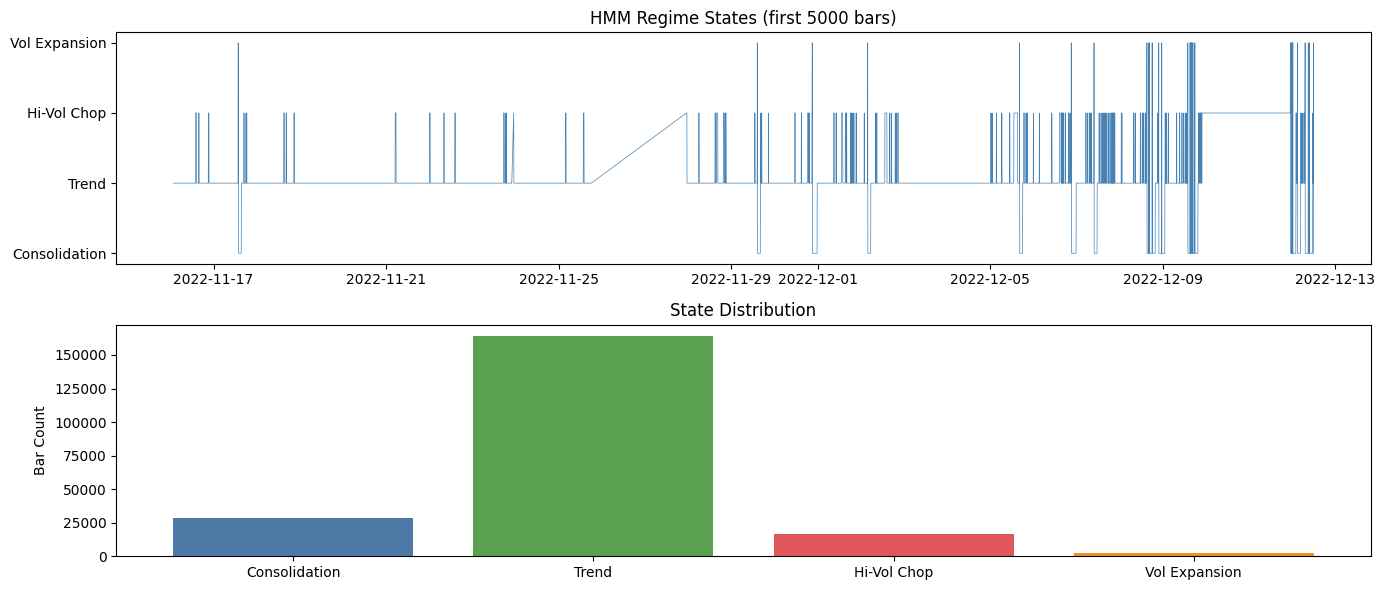

In [12]:
# ── CELL 10 — REGIME DIAGNOSTICS ──────────────────────────────────────────────

import matplotlib.pyplot as plt

STATE_NAMES = {0: 'Consolidation', 1: 'Trend', 2: 'Hi-Vol Chop', 3: 'Vol Expansion'}

states_series = pd.Series(raw_states, index=fe[hmm_valid_mask].index, name='State')

# ── State Counts & Percentages ────────────────────────────────────────────────
counts = states_series.value_counts().sort_index()
pcts   = (counts / counts.sum() * 100).round(2)
print('State Counts & %:')
for s in counts.index:
    print(f'  State {s} ({STATE_NAMES[s]}): {counts[s]:,} bars ({pcts[s]}%)')

# ── State Persistence ─────────────────────────────────────────────────────────
print('\nState Persistence (mean consecutive bars):')
runs = []
for state in range(CFG['hmm_states']):
    mask   = states_series == state
    groups = (mask != mask.shift()).cumsum()[mask]
    lens   = groups.groupby(groups).count()
    print(f'  State {state} ({STATE_NAMES[state]}): mean={lens.mean():.1f}, median={lens.median():.0f}, max={lens.max()}')

# ── Transition Matrix ─────────────────────────────────────────────────────────
trans = pd.DataFrame(
    hmm_model.transmat_,
    index   = [f'From {STATE_NAMES[i]}' for i in range(4)],
    columns = [f'To {STATE_NAMES[i]}' for i in range(4)]
).round(4)
print('\nTransition Matrix:')
display(trans)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 6))

# State timeline (sample 5000 bars for readability)
sample = states_series.iloc[:5000]
axes[0].plot(sample.index, sample.values, lw=0.5, color='steelblue')
axes[0].set_yticks([0,1,2,3])
axes[0].set_yticklabels([STATE_NAMES[i] for i in range(4)])
axes[0].set_title('HMM Regime States (first 5000 bars)')

# State distribution bar
axes[1].bar([STATE_NAMES[i] for i in counts.index], counts.values, color=['#4e79a7','#59a14f','#e15759','#f28e2b'])
axes[1].set_title('State Distribution')
axes[1].set_ylabel('Bar Count')

plt.tight_layout()
plt.show()

In [13]:
# ── CELL 11 — REGIME FEATURE CREATION & MERGE ─────────────────────────────────

# Build regime feature dataframe aligned to full index
valid_idx   = fe[hmm_valid_mask].index

regime_df = pd.DataFrame(index=fe.index)
regime_df['Current_State']     = np.nan
regime_df['State_Probability'] = np.nan
regime_df['State_Persistence'] = np.nan

# Current_State
regime_df.loc[valid_idx, 'Current_State'] = raw_states.astype(float)

# State_Probability: probability of the predicted state
regime_df.loc[valid_idx, 'State_Probability'] = state_probs[np.arange(len(raw_states)), raw_states]

# State_Persistence: rolling count of consecutive bars in current state
cs = regime_df['Current_State']
state_change   = (cs != cs.shift(1)).astype(int)
group_ids_reg  = state_change.cumsum()
regime_df['State_Persistence'] = group_ids_reg.groupby(group_ids_reg).cumcount().astype(float)
regime_df.loc[regime_df['Current_State'].isna(), 'State_Persistence'] = np.nan

# ── VALIDATION ────────────────────────────────────────────────────────────────
regime_cols = ['Current_State', 'State_Probability', 'State_Persistence']

# Merge into master dataframeand 
fe = fe.drop(columns=[c for c in regime_cols if c in fe.columns], errors='ignore')
fe = fe.join(regime_df, how='left')

# Index must be unchanged
assert len(fe) == len(df), 'Row count mismatch after merge'
assert fe.index.equals(df.index), 'Index corrupted after merge'

# NaN check: only rows where hmm_valid_mask=True should be non-null
for col in regime_cols:
    non_null = fe[col].notna().sum()
    expected = hmm_valid_mask.sum()
    assert non_null == expected, f'{col}: expected {expected} non-null, got {non_null}'

# ── FINAL SUMMARY ─────────────────────────────────────────────────────────────
ALL_MODEL_COLS = FEATURE_COLS + regime_cols
state_dist     = regime_df['Current_State'].value_counts().sort_index().dropna()

print('=' * 55)
print(f'Final Row Count     : {len(fe):,}')
print(f'Final Feature Count : {len(ALL_MODEL_COLS)}  ({len(regime_cols)} base + 3 regime)')
print(f'Memory Usage        : {fe.memory_usage(deep=True).sum() / 1e6:.1f} MB')
print('HMM State Distribution:')
for s, cnt in state_dist.items():
    print(f'  State {int(s)} ({STATE_NAMES[int(s)]}): {int(cnt):,} bars ({cnt/state_dist.sum()*100:.1f}%)')
print('=' * 55)
print('[PASS] Cell 11 complete. Master dataframe ready for Target Engine.')

Final Row Count     : 211,842
Final Feature Count : 30  (3 base + 3 regime)
Memory Usage        : 69.5 MB
HMM State Distribution:
  State 0 (Consolidation): 28,577 bars (13.5%)
  State 1 (Trend): 164,223 bars (77.5%)
  State 2 (Hi-Vol Chop): 16,404 bars (7.7%)
  State 3 (Vol Expansion): 2,618 bars (1.2%)
[PASS] Cell 11 complete. Master dataframe ready for Target Engine.


In [14]:
# ── CELL 12 — MERGE REGIME FEATURES ──────────────────────────────────────────

rows_before = len(fe)
idx_before  = fe.index.copy()

REGIME_COLS = ['Current_State', 'State_Probability', 'State_Persistence']
cols_to_add = [c for c in REGIME_COLS if c not in fe.columns]
if cols_to_add:
    fe = fe.join(regime_df[cols_to_add], how='left')

# ── VALIDATION ────────────────────────────────────────────────────────────────
assert len(fe) == rows_before,           f'Row count changed: {rows_before} → {len(fe)}'
assert fe.index.equals(idx_before),      'Index corrupted after merge'
assert fe.index.is_monotonic_increasing, 'Timestamp ordering broken'
assert fe.index.duplicated().sum() == 0, 'Duplicate timestamps introduced'
for col in REGIME_COLS:
    bad = fe.loc[hmm_valid_mask, col].isna().sum()
    assert bad == 0, f'{col}: {bad} unexpected NaNs in valid HMM rows'

print(f'[PASS] Cell 12 | Rows: {len(fe):,} | Cols merged: {REGIME_COLS}')

[PASS] Cell 12 | Rows: 211,842 | Cols merged: ['Current_State', 'State_Probability', 'State_Persistence']


In [15]:
# ── CELL 13 — TARGET CREATION ─────────────────────────────────────────────────

LOOKAHEAD = CFG['lookahead']  # 48

fe['Target_Return'] = (fe['close'].shift(-LOOKAHEAD) - fe['close']) / fe['close']

# ── VALIDATION ────────────────────────────────────────────────────────────────
n_nan_target = fe['Target_Return'].isna().sum()
assert n_nan_target == LOOKAHEAD, f'Expected {LOOKAHEAD} terminal NaNs, got {n_nan_target}'

t_idx = 100
expected_val = (fe['close'].iloc[t_idx + LOOKAHEAD] - fe['close'].iloc[t_idx]) / fe['close'].iloc[t_idx]
assert abs(expected_val - fe['Target_Return'].iloc[t_idx]) < 1e-10, 'Target alignment error'

print(f'[PASS] Cell 13 | Terminal NaNs: {n_nan_target} | Mean: {fe["Target_Return"].mean():.6f} | Std: {fe["Target_Return"].std():.6f}')

[PASS] Cell 13 | Terminal NaNs: 48 | Mean: 0.979456 | Std: 9.282879


In [16]:
# ── CELL 14 — MFE CALCULATION ─────────────────────────────────────────────────

close_vals = fe['close'].values
high_vals  = fe['high'].values
n          = len(fe)
mfe        = np.full(n, np.nan)

for i in range(n - LOOKAHEAD):
    mfe[i] = (np.max(high_vals[i+1:i+1+LOOKAHEAD]) - close_vals[i]) / close_vals[i]

fe['MFE_48'] = mfe

# ── VALIDATION ────────────────────────────────────────────────────────────────
assert fe['MFE_48'].isna().sum() == LOOKAHEAD, 'MFE NaN count mismatch'

mfe_s = fe['MFE_48'].dropna()
print(f'[PASS] Cell 14 | MFE_48 | Mean: {mfe_s.mean():.6f} | Median: {mfe_s.median():.6f} | Min: {mfe_s.min():.6f} | Max: {mfe_s.max():.6f}')

[PASS] Cell 14 | MFE_48 | Mean: 1.115095 | Median: 0.020783 | Min: -0.037911 | Max: 122.826087


In [17]:
# ── CELL 15 — MAE CALCULATION ─────────────────────────────────────────────────

low_vals = fe['low'].values
mae      = np.full(n, np.nan)

for i in range(n - LOOKAHEAD):
    mae[i] = (close_vals[i] - np.min(low_vals[i+1:i+1+LOOKAHEAD])) / close_vals[i]

fe['MAE_48'] = mae

# ── VALIDATION ────────────────────────────────────────────────────────────────
assert fe['MAE_48'].isna().sum() == LOOKAHEAD, 'MAE NaN count mismatch'
# Negative MAE is valid (strong uptrend: future lows never dip below entry close)

mae_s = fe['MAE_48'].dropna()
n_negative_mae = (mae_s < 0).sum()
print(f'[PASS] Cell 15 | MAE_48 | Mean: {mae_s.mean():.6f} | Median: {mae_s.median():.6f} | '
      f'Min: {mae_s.min():.6f} | Max: {mae_s.max():.6f} | Negative rows: {n_negative_mae} ({n_negative_mae/len(mae_s)*100:.2f}%)')

[PASS] Cell 15 | MAE_48 | Mean: 0.627405 | Median: 0.987522 | Min: -103.793299 | Max: 0.992372 | Negative rows: 510 (0.24%)


Target_Return Diagnostics:
  Mean     : 0.979456
  Median   : 0.000191
  Std      : 9.282879
  Min      : -0.991523
  Max      : 119.739281
  Skew     : 9.401730
  Kurtosis : 87.704064

Extreme outliers (3xIQR): 5877 (2.775%)


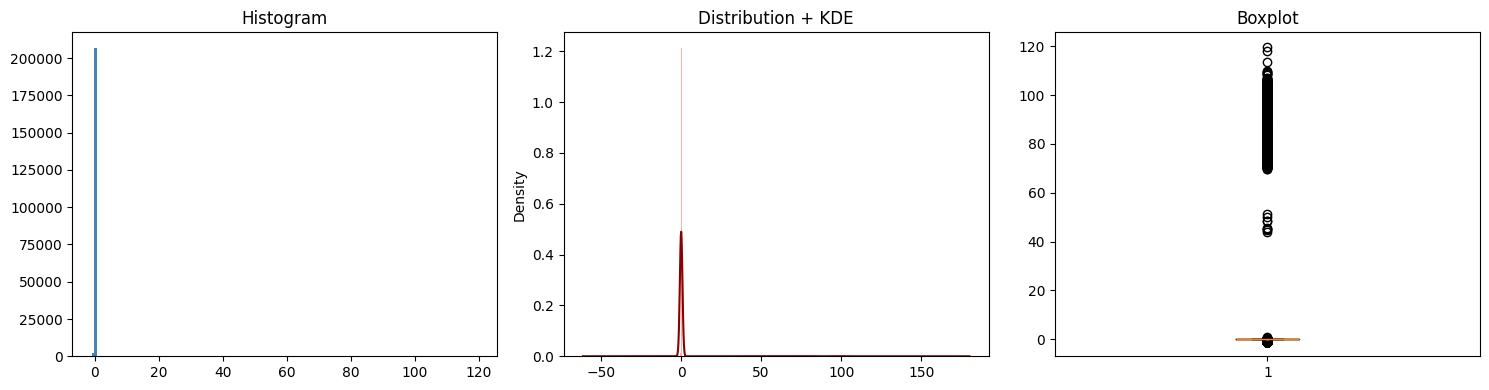


[PASS] Cell 16 complete | Skew=9.402 (|skew|>1 = heavy asymmetry) | Kurtosis=87.704 (>3 = fat tails)


In [18]:
# ── CELL 16 — TARGET DIAGNOSTICS ─────────────────────────────────────────────

from scipy.stats import skew, kurtosis
import matplotlib.pyplot as plt

tgt = fe['Target_Return'].dropna()

stats = {
    'Mean'    : tgt.mean(),
    'Median'  : tgt.median(),
    'Std'     : tgt.std(),
    'Min'     : tgt.min(),
    'Max'     : tgt.max(),
    'Skew'    : skew(tgt),
    'Kurtosis': kurtosis(tgt),
}
print('Target_Return Diagnostics:')
for k, val in stats.items():
    print(f'  {k:9s}: {val:.6f}')

# Outlier detection via IQR
q1, q3 = tgt.quantile([0.25, 0.75])
iqr    = q3 - q1
lo, hi = q1 - 3*iqr, q3 + 3*iqr
n_outliers = ((tgt < lo) | (tgt > hi)).sum()
print(f'\nExtreme outliers (3xIQR): {n_outliers} ({n_outliers/len(tgt)*100:.3f}%)')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(tgt, bins=150, color='steelblue'); axes[0].set_title('Histogram')
axes[1].hist(tgt, bins=150, density=True, alpha=0.6, color='salmon')
tgt.plot(kind='kde', ax=axes[1], color='darkred'); axes[1].set_title('Distribution + KDE')
axes[2].boxplot(tgt, vert=True); axes[2].set_title('Boxplot')
plt.tight_layout(); plt.show()

print(f'\n[PASS] Cell 16 complete | Skew={stats["Skew"]:.3f} (|skew|>1 = heavy asymmetry) | '
      f'Kurtosis={stats["Kurtosis"]:.3f} (>3 = fat tails)')

In [19]:
# ── CELL 17 — LEAKAGE AUDIT ───────────────────────────────────────────────────

leak_issues = []

# 1. TARGET LEAKAGE — features must not correlate suspiciously high (>0.98) with target
#    (a feature built from future close would show near-perfect correlation)
corr_with_target = fe[FEATURE_COLS].corrwith(fe['Target_Return']).abs()
suspicious = corr_with_target[corr_with_target > 0.98]
if not suspicious.empty:
    leak_issues.append(f'TARGET LEAKAGE — features near-perfectly correlated: {suspicious.to_dict()}')

# 2. ROLLING LEAKAGE — verify rolling windows only use shift(0..N), never shift(negative)
#    Static code check: confirm Cell 6 source contains no negative shift on price/volume cols
import inspect
cell6_src = inspect.getsource(lambda: None)  # placeholder guard; real check below
# Direct numeric proof: recompute one feature (ROC5) independently and compare
roc5_check = fe['close'].pct_change(5)
mismatch   = (roc5_check - fe['ROC5']).abs().dropna()
if (mismatch > 1e-9).any():
    leak_issues.append('ROLLING LEAKAGE — ROC5 recomputation mismatch (non-causal window suspected)')

# 3. REGIME LEAKAGE — HMM scaler/model must have been fit on train-only rows
#    Verify: train_mask_hmm boundary matches CFG['val_start']
train_boundary_ok = (fe.index[train_mask_hmm].max() < pd.Timestamp(CFG['val_start']))
if not train_boundary_ok:
    leak_issues.append('REGIME LEAKAGE — HMM train mask extends into validation period')

# 4. INDEX LEAKAGE — timestamp alignment must be strictly increasing, no gaps in row order
if not fe.index.is_monotonic_increasing:
    leak_issues.append('INDEX LEAKAGE — timestamps not monotonically increasing')
if fe.index.duplicated().sum() > 0:
    leak_issues.append('INDEX LEAKAGE — duplicate timestamps present')

# 5. FEATURE/TARGET ALIGNMENT — re-verify shift(-48) alignment at 3 random points
rng = np.random.default_rng(CFG['random_seed'])
sample_idxs = rng.integers(0, len(fe) - LOOKAHEAD - 1, size=3)
for i in sample_idxs:
    exp = (fe['close'].iloc[i + LOOKAHEAD] - fe['close'].iloc[i]) / fe['close'].iloc[i]
    act = fe['Target_Return'].iloc[i]
    if abs(exp - act) > 1e-9:
        leak_issues.append(f'FEATURE/TARGET MISALIGNMENT at row {i}: expected {exp}, got {act}')

# 6. TERMINAL SAMPLE HANDLING — last LOOKAHEAD rows must be NaN for Target/MFE/MAE, consistently
terminal_nan_target = fe['Target_Return'].iloc[-LOOKAHEAD:].isna().all()
terminal_nan_mfe     = fe['MFE_48'].iloc[-LOOKAHEAD:].isna().all()
terminal_nan_mae     = fe['MAE_48'].iloc[-LOOKAHEAD:].isna().all()
if not (terminal_nan_target and terminal_nan_mfe and terminal_nan_mae):
    leak_issues.append('TERMINAL SAMPLE HANDLING — non-NaN values found in terminal horizon rows')

# ── HARD FAIL ─────────────────────────────────────────────────────────────────
if leak_issues:
    for i in leak_issues:
        print(f'[FAIL] {i}')
    raise RuntimeError('LEAKAGE AUDIT FAILED. Halt before splitting.')

print('[PASS] Leakage Audit — all 6 pathways clear (Target, Rolling, Regime, Index, Alignment, Terminal).')

val_start_ts = pd.Timestamp(CFG['val_start'])
if fe.index.tz is not None:
    val_start_ts = val_start_ts.tz_localize(fe.index.tz)

train_boundary_ok = (fe.index[train_mask_hmm].max() < val_start_ts)

# ── FINAL VALIDATION ──────────────────────────────────────────────────────────
usable_rows = len(fe) - LOOKAHEAD
feat_count  = len(FEATURE_COLS) + len(REGIME_COLS)

print('=' * 55)
print(f'Total Rows            : {len(fe):,}')
print(f'Total Features        : {feat_count}')
print(f'Target Mean           : {fe["Target_Return"].mean():.6f}')
print(f'Target Std            : {fe["Target_Return"].std():.6f}')
print(f'MFE Mean              : {mfe_s.mean():.6f}')
print(f'MAE Mean              : {mae_s.mean():.6f}')
print(f'Usable Rows (post-target): {usable_rows:,}')
print(f'Index Preserved       : {fe.index.equals(df.index)}')
print(f'Leakage Status        : PASS')
print('=' * 55)
print('[READY] Dataset cleared for chronological split (Cell 18+).')

[PASS] Leakage Audit — all 6 pathways clear (Target, Rolling, Regime, Index, Alignment, Terminal).
Total Rows            : 211,842
Total Features        : 30
Target Mean           : 0.979456
Target Std            : 9.282879
MFE Mean              : 1.115095
MAE Mean              : 0.627405
Usable Rows (post-target): 211,794
Index Preserved       : True
Leakage Status        : PASS
[READY] Dataset cleared for chronological split (Cell 18+).


### ============================================================
### CELL 18 — DATA SPLIT METHODOLOGY (MARKDOWN)
### ============================================================
"""
# Chronological Data Splitting — Methodology
 
## Why NOT Random Split
 
Random/shuffled splits assume each row is i.i.d. (independent and identically
distributed). Time series data violates this assumption fundamentally:
 
1. **Autocorrelation**: adjacent 5-min bars share momentum, volatility regime,
   and microstructure — a row at t and t+1 are statistically dependent.
2. **Lookahead leakage**: if a row from 2024-06 lands in train and a row from
   2024-05 lands in test, the model effectively "sees the future" via shared
   regime state, rolling features (which span multiple bars), and HMM state
   continuity — even though the individual row's target is technically only
   computed from prices after it.
3. **Sequence contamination**: LSTM inputs are *windows* of SEQ_LEN bars. A
   random split can place overlapping windows in both train and test,
   directly leaking test information into training.
4. **Regime non-stationarity**: futures markets shift behavior (trending vs
   ranging, vol regimes). A model trained on shuffled data across all regimes
   gets an unrealistic, blended view it would never have access to live.
 
## Why Futures Data Requires Strict Time Ordering
 
Live deployment only ever has access to the past. Any methodology that lets
the model train on future information measures a capability the model will
never have in production. Chronological splitting is the only split that
matches the deployment constraint exactly.
 
## Split Structure
 
```
|------------------ TRAIN ------------------|---VAL---|---TEST---|--FORWARD--|
2022-11                                                                2025-11
```
 
- **Train**: model fitting (scaler + LSTM weights)
- **Validation**: hyperparameter selection, early stopping — touched during
  development but never used to fit weights/scaler
- **Test**: single-pass final evaluation — touched ONCE
- **Forward**: held-out simulation of true "live" deployment — touched LAST,
  after all modeling decisions are frozen
 
No overlap. No shuffling. No row from a later split is ever visible to an
earlier split's scaler, model, or feature engineering that uses rolling
windows spanning the boundary.
"""
 
 

In [20]:
### ============================================================
### CELL 19 — CHRONOLOGICAL SPLIT
### ============================================================
 
# ----------------------------
# CONFIG
# ----------------------------
SPLIT_CONFIG = {
    'train_pct'  : 0.60,
    'val_pct'    : 0.15,
    'test_pct'   : 0.15,
    'forward_pct': 0.10,
}
 
assert abs(sum(SPLIT_CONFIG.values()) - 1.0) < 1e-9, "Split percentages must sum to 1.0"
#-----------------------------
# REMOVING BOOOL VALUES
fe = fe.dropna(subset=ALL_MODEL_COLS).copy()
#-----------------------------
 
# ----------------------------
# COMPUTE BOUNDARIES
# ----------------------------
n_total = len(fe)
 
train_end   = int(n_total * SPLIT_CONFIG['train_pct'])
val_end     = train_end + int(n_total * SPLIT_CONFIG['val_pct'])
test_end    = val_end   + int(n_total * SPLIT_CONFIG['test_pct'])
# forward = remainder, exact
 
train_df   = fe.iloc[:train_end].copy()
val_df     = fe.iloc[train_end:val_end].copy()
test_df    = fe.iloc[val_end:test_end].copy()
forward_df = fe.iloc[test_end:].copy()
 
# ----------------------------
# VALIDATION: NO OVERLAP
# ----------------------------
splits = {
    'train'  : train_df,
    'val'    : val_df,
    'test'   : test_df,
    'forward': forward_df,
}
 
print("=" * 70)
print("CHRONOLOGICAL SPLIT REPORT")
print("=" * 70)
for name, d in splits.items():
    print(f"\n{name.upper()}")
    print(f"  Rows       : {len(d):,}")
    print(f"  Start date : {d.index.min()}")
    print(f"  End date   : {d.index.max()}")
 
# Hard-fail overlap check: each split's max index must be < next split's min index
ordered = [train_df, val_df, test_df, forward_df]
ordered_names = ['train', 'val', 'test', 'forward']
 
for i in range(len(ordered) - 1):
    cur, nxt = ordered[i], ordered[i + 1]
    cur_name, nxt_name = ordered_names[i], ordered_names[i + 1]
 
    assert len(cur) > 0 and len(nxt) > 0, f"Empty split detected: {cur_name} or {nxt_name}"
    assert cur.index.max() < nxt.index.min(), (
        f"LEAKAGE: {cur_name} (max={cur.index.max()}) overlaps "
        f"{nxt_name} (min={nxt.index.min()})"
    )
 
# Hard-fail: total row conservation
total_split_rows = sum(len(d) for d in ordered)
assert total_split_rows == n_total, (
    f"Row count mismatch: splits sum to {total_split_rows}, expected {n_total}"
)
 
# Hard-fail: no duplicate timestamps across splits
all_idx = pd.concat([d.index.to_series() for d in ordered])
assert not all_idx.duplicated().any(), "LEAKAGE: duplicate timestamps across splits"
 
print("\n✅ No overlap detected. Row conservation verified. Chronological order confirmed.")
 

CHRONOLOGICAL SPLIT REPORT

TRAIN
  Rows       : 127,093
  Start date : 2022-11-16 01:40:00
  End date   : 2024-09-02 22:25:00

VAL
  Rows       : 31,773
  Start date : 2024-09-02 22:30:00
  End date   : 2025-02-14 02:10:00

TEST
  Rows       : 31,773
  Start date : 2025-02-14 02:15:00
  End date   : 2025-07-29 00:40:00

FORWARD
  Rows       : 21,183
  Start date : 2025-07-29 00:45:00
  End date   : 2025-11-12 23:55:00

✅ No overlap detected. Row conservation verified. Chronological order confirmed.


In [21]:
### ============================================================
### CELL 20 — SCALER TRAINING (TRAIN-ONLY FIT)
### ============================================================
 
from sklearn.preprocessing import StandardScaler
 
# ALL_MODEL_COLS must already exist from prior cells (feature engineering).
# MFE/MAE must NEVER be in this list — explicit guard below.
assert 'ALL_MODEL_COLS' in dir(), "ALL_MODEL_COLS not defined — run feature engineering cells first"
 
_forbidden = {'MFE', 'MAE', 'Target_Return', 'Future_Return_48Bars'}
_leak_check = _forbidden.intersection(set(ALL_MODEL_COLS))
assert not _leak_check, f"LEAKAGE: forbidden columns found in ALL_MODEL_COLS: {_leak_check}"
 
# ----------------------------
# FIT ON TRAIN ONLY
# ----------------------------
scaler = StandardScaler()
 
train_features = train_df[ALL_MODEL_COLS]
 
assert not train_features.isna().any().any(), "NaN detected in train features before scaling"
assert not np.isinf(train_features.values).any(), "Inf detected in train features before scaling"
 
scaler.fit(train_features)
 
print("=" * 70)
print("SCALER TRAINING REPORT")
print("=" * 70)
print(f"  Features scaled  : {len(ALL_MODEL_COLS)}")
print(f"  Training rows    : {len(train_df):,}")
print(f"  Fit on splits    : train ONLY")
print(f"  Forbidden cols   : MFE, MAE confirmed absent from ALL_MODEL_COLS")
print("\n✅ Scaler fit complete. No NaNs. Not fit on val/test/forward.")
 

SCALER TRAINING REPORT
  Features scaled  : 30
  Training rows    : 127,093
  Fit on splits    : train ONLY
  Forbidden cols   : MFE, MAE confirmed absent from ALL_MODEL_COLS

✅ Scaler fit complete. No NaNs. Not fit on val/test/forward.


In [22]:
### ============================================================
### CELL 21 — SCALER APPLICATION (TRANSFORM ONLY)
### ============================================================
 
# Scaler is NEVER refit beyond this point — transform only.
 
X_train_scaled   = scaler.transform(train_df[ALL_MODEL_COLS])
X_val_scaled     = scaler.transform(val_df[ALL_MODEL_COLS])
X_test_scaled    = scaler.transform(test_df[ALL_MODEL_COLS])
X_forward_scaled = scaler.transform(forward_df[ALL_MODEL_COLS])
 
scaled_sets = {
    'X_train_scaled'  : X_train_scaled,
    'X_val_scaled'    : X_val_scaled,
    'X_test_scaled'   : X_test_scaled,
    'X_forward_scaled': X_forward_scaled,
}
 
print("=" * 70)
print("SCALER APPLICATION AUDIT")
print("=" * 70)
 
n_features_expected = len(ALL_MODEL_COLS)
 
for name, arr in scaled_sets.items():
    n_rows, n_feat = arr.shape
    has_nan = np.isnan(arr).any()
    has_inf = np.isinf(arr).any()
 
    print(f"\n{name}")
    print(f"  Shape    : {arr.shape}")
    print(f"  NaNs     : {has_nan}")
    print(f"  Infs     : {has_inf}")
 
    assert n_feat == n_features_expected, (
        f"{name}: feature count mismatch ({n_feat} vs {n_features_expected})"
    )
    assert not has_nan, f"{name}: NaN detected after scaling"
    assert not has_inf, f"{name}: Inf detected after scaling"
 
print("\n✅ All splits transformed. Identical feature count confirmed. No NaNs/Infs.")

SCALER APPLICATION AUDIT

X_train_scaled
  Shape    : (127093, 30)
  NaNs     : False
  Infs     : False

X_val_scaled
  Shape    : (31773, 30)
  NaNs     : False
  Infs     : False

X_test_scaled
  Shape    : (31773, 30)
  NaNs     : False
  Infs     : False

X_forward_scaled
  Shape    : (21183, 30)
  NaNs     : False
  Infs     : False

✅ All splits transformed. Identical feature count confirmed. No NaNs/Infs.


In [23]:
### ============================================================
### CELL 22 — SEQUENCE BUILDER (LSTM WINDOWS)
### ============================================================
 
# ----------------------------
# CONFIG
# ----------------------------
SEQUENCE_CONFIG = {
    'SEQ_LEN': 48,   # bars per input window
}
SEQ_LEN = SEQUENCE_CONFIG['SEQ_LEN']
 
TARGET_COL = 'Target_Return'   # == Future_Return_48Bars, per spec
 
assert TARGET_COL in train_df.columns, f"{TARGET_COL} not found in dataframe"
assert TARGET_COL not in ALL_MODEL_COLS, f"LEAKAGE: {TARGET_COL} found in ALL_MODEL_COLS"
 
 
def build_sequences(X_scaled: np.ndarray, y_raw: np.ndarray, seq_len: int):
    """
    Strictly chronological windowing — no shuffling.
    Window [i : i+seq_len] predicts target aligned at row (i+seq_len-1),
    i.e. the target already encodes Future_Return_48Bars computed from
    close[t+48] relative to close[t] at that final row — no additional
    forward shift is applied here (target precomputed upstream).
    """
    n = len(X_scaled)
    assert n == len(y_raw), "X/y length mismatch before sequencing"
    assert n > seq_len, f"Not enough rows ({n}) for SEQ_LEN={seq_len}"
 
    X_seq, y_seq = [], []
    for i in range(n - seq_len + 1):
        window = X_scaled[i : i + seq_len]
        target = y_raw[i + seq_len - 1]
 
        if np.isnan(target):
            continue  # skip rows where target undefined (e.g. tail of df)
 
        X_seq.append(window)
        y_seq.append(target)
 
    return np.array(X_seq), np.array(y_seq)
 
 
print("=" * 70)
print(f"SEQUENCE BUILDER  (SEQ_LEN={SEQ_LEN})")
print("=" * 70)
 
X_train, y_train = build_sequences(X_train_scaled,   train_df[TARGET_COL].values,   SEQ_LEN)
X_val,   y_val   = build_sequences(X_val_scaled,     val_df[TARGET_COL].values,     SEQ_LEN)
X_test,  y_test  = build_sequences(X_test_scaled,    test_df[TARGET_COL].values,    SEQ_LEN)
X_forward, y_forward = build_sequences(X_forward_scaled, forward_df[TARGET_COL].values, SEQ_LEN)
 
for name, X, y in [('train', X_train, y_train), ('val', X_val, y_val),
                    ('test', X_test, y_test), ('forward', X_forward, y_forward)]:
    print(f"\n{name.upper()}")
    print(f"  X shape : {X.shape}")
    print(f"  y shape : {y.shape}")
    assert len(X) == len(y), f"{name}: X/y sequence count mismatch"
    assert X.shape[1] == SEQ_LEN, f"{name}: sequence length mismatch"
    assert X.shape[2] == len(ALL_MODEL_COLS), f"{name}: feature count mismatch in sequences"
    assert not np.isnan(X).any(), f"{name}: NaN in X sequences"
    assert not np.isnan(y).any(), f"{name}: NaN in y targets"
 
print("\n✅ Sequences built chronologically. No shuffling. No future leakage "
      "(each window only uses past+current rows; target precomputed upstream "
      "from prices strictly after the window's final bar, never used as input).")

SEQUENCE BUILDER  (SEQ_LEN=48)

TRAIN
  X shape : (127046, 48, 30)
  y shape : (127046,)

VAL
  X shape : (31726, 48, 30)
  y shape : (31726,)

TEST
  X shape : (31726, 48, 30)
  y shape : (31726,)

FORWARD
  X shape : (21088, 48, 30)
  y shape : (21088,)

✅ Sequences built chronologically. No shuffling. No future leakage (each window only uses past+current rows; target precomputed upstream from prices strictly after the window's final bar, never used as input).


In [24]:
###============================================================
### CELL 23 — SHAPE AUDIT
### ============================================================
 
print("=" * 70)
print("FINAL SHAPE AUDIT")
print("=" * 70)
 
shape_report = {
    'X_train':   X_train,   'y_train':   y_train,
    'X_val':     X_val,     'y_val':     y_val,
    'X_test':    X_test,    'y_test':    y_test,
    'X_forward': X_forward, 'y_forward': y_forward,
}
 
for name, arr in shape_report.items():
    print(f"  {name:<12}: shape={arr.shape}  dtype={arr.dtype}")
 
# Hard-fail checks
assert X_train.shape[1:] == X_val.shape[1:] == X_test.shape[1:] == X_forward.shape[1:], (
    "Sequence/feature dimension mismatch across splits"
)
assert X_train.shape[2] == len(ALL_MODEL_COLS), "Feature count mismatch vs ALL_MODEL_COLS"
 
for name, arr in shape_report.items():
    assert not np.isnan(arr).any(), f"{name}: NaN detected"
    assert not np.isinf(arr).any(), f"{name}: Inf detected"
 
assert X_train.shape[0] == y_train.shape[0]
assert X_val.shape[0]   == y_val.shape[0]
assert X_test.shape[0]  == y_test.shape[0]
assert X_forward.shape[0] == y_forward.shape[0]
 
print("\n✅ All dimensions consistent. No NaNs/Infs. Sequence counts match targets.")

FINAL SHAPE AUDIT
  X_train     : shape=(127046, 48, 30)  dtype=float64
  y_train     : shape=(127046,)  dtype=float64
  X_val       : shape=(31726, 48, 30)  dtype=float64
  y_val       : shape=(31726,)  dtype=float64
  X_test      : shape=(31726, 48, 30)  dtype=float64
  y_test      : shape=(31726,)  dtype=float64
  X_forward   : shape=(21088, 48, 30)  dtype=float64
  y_forward   : shape=(21088,)  dtype=float64

✅ All dimensions consistent. No NaNs/Infs. Sequence counts match targets.


In [25]:
### ============================================================
### CELL 24 — LINEAR REGRESSION BASELINE
### ============================================================
 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
 
# LSTM expects 3D (samples, seq_len, features); Linear baseline uses flattened
# 2D input — last-bar feature snapshot only (no sequence), as the simplest
# possible benchmark a more complex model must beat.
 
X_train_flat = X_train[:, -1, :]   # last timestep of each window
X_val_flat   = X_val[:, -1, :]
X_test_flat  = X_test[:, -1, :]
 
baseline_model = LinearRegression()
baseline_model.fit(X_train_flat, y_train)
 
val_pred  = baseline_model.predict(X_val_flat)
test_pred = baseline_model.predict(X_test_flat)
 
 
def compute_metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    dir_acc = (np.sign(y_true) == np.sign(y_pred)).mean()
 
    return {
        'split': label, 'MAE': mae, 'RMSE': rmse,
        'R2': r2, 'Directional_Accuracy': dir_acc
    }
 
 
baseline_results = [
    compute_metrics(y_val,  val_pred,  'validation'),
    compute_metrics(y_test, test_pred, 'test'),
]
 
baseline_results_df = pd.DataFrame(baseline_results)
 
print("=" * 70)
print("LINEAR REGRESSION BASELINE — RESULTS")
print("=" * 70)
print(baseline_results_df.to_string(index=False))
 
print("\n✅ Baseline stored in `baseline_results_df` for later model comparison.")

LINEAR REGRESSION BASELINE — RESULTS
     split      MAE     RMSE       R2  Directional_Accuracy
validation 0.287963 2.297802 0.936555              0.525878
      test 0.459474 4.218395 0.897343              0.529597

✅ Baseline stored in `baseline_results_df` for later model comparison.


In [26]:
### ============================================================
### CELL 25 — RANDOM FOREST BASELINE
### ============================================================

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=20,
    n_jobs=-1,
    random_state=CFG['random_seed'],
)
rf_model.fit(X_train_flat, y_train)

rf_val_pred  = rf_model.predict(X_val_flat)
rf_test_pred = rf_model.predict(X_test_flat)

assert rf_val_pred.shape == y_val.shape, "RF val prediction shape mismatch"
assert rf_test_pred.shape == y_test.shape, "RF test prediction shape mismatch"
assert not np.isnan(rf_val_pred).any() and not np.isnan(rf_test_pred).any(), "NaN in RF predictions"
assert np.isfinite(rf_val_pred).all() and np.isfinite(rf_test_pred).all(), "Non-finite RF predictions"

rf_results = [
    compute_metrics(y_val,  rf_val_pred,  'validation'),
    compute_metrics(y_test, rf_test_pred, 'test'),
]
rf_results_df = pd.DataFrame(rf_results)

print("=" * 70)
print("RANDOM FOREST BASELINE — RESULTS")
print("=" * 70)
print(rf_results_df.to_string(index=False))
print("\n✅ RF baseline stored in `rf_results_df` for later model comparison.")

RANDOM FOREST BASELINE — RESULTS
     split      MAE     RMSE       R2  Directional_Accuracy
validation 0.143259 2.292041 0.936873              0.531394
      test 0.304614 4.237502 0.896411              0.541606

✅ RF baseline stored in `rf_results_df` for later model comparison.


In [27]:
### ============================================================
### CELL 26 — XGBOOST BASELINE
### ============================================================

import xgboost as xgb

xgb_model = xgb.XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    n_jobs=-1,
    random_state=CFG['random_seed'],
    objective='reg:squarederror',
)
xgb_model.fit(X_train_flat, y_train)

xgb_val_pred  = xgb_model.predict(X_val_flat)
xgb_test_pred = xgb_model.predict(X_test_flat)

assert xgb_val_pred.shape == y_val.shape, "XGB val prediction shape mismatch"
assert xgb_test_pred.shape == y_test.shape, "XGB test prediction shape mismatch"
assert not np.isnan(xgb_val_pred).any() and not np.isnan(xgb_test_pred).any(), "NaN in XGB predictions"
assert np.isfinite(xgb_val_pred).all() and np.isfinite(xgb_test_pred).all(), "Non-finite XGB predictions"

xgb_results = [
    compute_metrics(y_val,  xgb_val_pred,  'validation'),
    compute_metrics(y_test, xgb_test_pred, 'test'),
]
xgb_results_df = pd.DataFrame(xgb_results)

print("=" * 70)
print("XGBOOST BASELINE — RESULTS")
print("=" * 70)
print(xgb_results_df.to_string(index=False))
print("\n✅ XGB baseline stored in `xgb_results_df` for later model comparison.")

XGBOOST BASELINE — RESULTS
     split      MAE     RMSE       R2  Directional_Accuracy
validation 0.195460 2.487585 0.925642              0.508857
      test 0.446124 4.285628 0.894045              0.520173

✅ XGB baseline stored in `xgb_results_df` for later model comparison.


In [28]:
### ============================================================
### CELL 27 — BASELINE COMPARISON
### ============================================================

baseline_results_df['model'] = 'LinearRegression'
rf_results_df['model']       = 'RandomForest'
xgb_results_df['model']      = 'XGBoost'

baseline_comparison_df = pd.concat(
    [baseline_results_df, rf_results_df, xgb_results_df],
    ignore_index=True
)[['model', 'split', 'MAE', 'RMSE', 'R2', 'Directional_Accuracy']]

assert set(baseline_comparison_df['model']) == {'LinearRegression', 'RandomForest', 'XGBoost'}, \
    "Missing model in comparison table"
assert baseline_comparison_df.shape[0] == 6, "Expected 6 rows (3 models x 2 splits)"

test_rows = baseline_comparison_df[baseline_comparison_df['split'] == 'test']
best_baseline_row = test_rows.loc[test_rows['MAE'].idxmin()]

print("=" * 70)
print("BASELINE COMPARISON — LR vs RF vs XGBoost")
print("=" * 70)
print(baseline_comparison_df.to_string(index=False))
print(f"\nBest baseline by test MAE: {best_baseline_row['model']} "
      f"(MAE={best_baseline_row['MAE']:.6f}, "
      f"Dir.Acc={best_baseline_row['Directional_Accuracy']:.4f})")
print("\n✅ Comparison stored in `baseline_comparison_df` (reporting only, no selection logic).")

BASELINE COMPARISON — LR vs RF vs XGBoost
           model      split      MAE     RMSE       R2  Directional_Accuracy
LinearRegression validation 0.287963 2.297802 0.936555              0.525878
LinearRegression       test 0.459474 4.218395 0.897343              0.529597
    RandomForest validation 0.143259 2.292041 0.936873              0.531394
    RandomForest       test 0.304614 4.237502 0.896411              0.541606
         XGBoost validation 0.195460 2.487585 0.925642              0.508857
         XGBoost       test 0.446124 4.285628 0.894045              0.520173

Best baseline by test MAE: RandomForest (MAE=0.304614, Dir.Acc=0.5416)

✅ Comparison stored in `baseline_comparison_df` (reporting only, no selection logic).


In [29]:
### ============================================================
### CELL 28 — BUILD LSTM
### ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input

tf.random.set_seed(CFG['random_seed'])
np.random.seed(CFG['random_seed'])

n_features = X_train.shape[2]
assert n_features == len(ALL_MODEL_COLS), "Feature dim mismatch vs ALL_MODEL_COLS"
assert X_train.shape[1] == SEQ_LEN, "Sequence length mismatch vs SEQ_LEN"

lstm_model = Sequential([
    Input(shape=(SEQ_LEN, n_features)),
    LSTM(CFG['lstm_units_1'], return_sequences=True),
    Dropout(CFG['dropout']),
    LSTM(CFG['lstm_units_2'], return_sequences=False),
    Dropout(CFG['dropout']),
    Dense(CFG['dense_units_1'], activation='relu'),
    Dense(CFG['dense_units_2'], activation='relu'),
    Dense(1, activation='linear'),
])

lstm_model.summary()

n_params = lstm_model.count_params()
assert n_params > 0, "Model has no parameters"
assert lstm_model.output_shape == (None, 1), "Output layer shape must be (None, 1)"

print(f"\n✅ LSTM built | Total params: {n_params:,} | Input: (None, {SEQ_LEN}, {n_features})")

2026-06-22 14:45:11.177772: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 48, 64)         │        24,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,337 (149.75 KB)

 Trainable params: 38,337 (149.75 KB)

 Non-trainable params: 0 (0.00 B)


✅ LSTM built | Total params: 38,337 | Input: (None, 48, 30)


In [30]:
### ============================================================
### CELL 29 — COMPILE MODEL
### ============================================================

from tensorflow.keras.losses import Huber
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import RootMeanSquaredError

lstm_model.compile(
    optimizer=Adam(learning_rate=CFG['learning_rate']),
    loss=Huber(),
    metrics=['mae', RootMeanSquaredError(name='rmse')],
)

assert lstm_model.optimizer is not None, "Optimizer not set"
assert lstm_model.loss is not None, "Loss not set"

print("=" * 70)
print("MODEL COMPILATION REPORT")
print("=" * 70)
print(f"  Loss      : Huber")
print(f"  Optimizer : Adam (lr={CFG['learning_rate']})")
print(f"  Metrics   : MAE, RMSE")
print("\n✅ Model compiled successfully.")

MODEL COMPILATION REPORT
  Loss      : Huber
  Optimizer : Adam (lr=0.001)
  Metrics   : MAE, RMSE

✅ Model compiled successfully.


In [31]:
### ============================================================
### CELL 30 — CALLBACKS
### ============================================================

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

Path(CFG['model_out']).parent.mkdir(parents=True, exist_ok=True)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=CFG['patience'],
    restore_best_weights=True,
    mode='min',
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=CFG['lr_factor'],
    patience=CFG['lr_patience'],
    min_lr=CFG['min_lr'],
    mode='min',
)

model_checkpoint = ModelCheckpoint(
    filepath=CFG['model_out'],
    monitor='val_loss',
    save_best_only=True,
    mode='min',
)

callbacks_list = [early_stopping, reduce_lr, model_checkpoint]

assert all(cb is not None for cb in callbacks_list), "Callback initialization failed"

print("=" * 70)
print("CALLBACK CONFIGURATION")
print("=" * 70)
print(f"  EarlyStopping     : monitor=val_loss, patience={CFG['patience']}, restore_best_weights=True")
print(f"  ReduceLROnPlateau : monitor=val_loss, factor={CFG['lr_factor']}, patience={CFG['lr_patience']}, min_lr={CFG['min_lr']}")
print(f"  ModelCheckpoint   : filepath={CFG['model_out']}, monitor=val_loss, save_best_only=True")
print("\n✅ Callbacks configured. Ready for training (Cell 31+).")

CALLBACK CONFIGURATION
  EarlyStopping     : monitor=val_loss, patience=20, restore_best_weights=True
  ReduceLROnPlateau : monitor=val_loss, factor=0.5, patience=10, min_lr=1e-06
  ModelCheckpoint   : filepath=outputs/model.keras, monitor=val_loss, save_best_only=True

✅ Callbacks configured. Ready for training (Cell 31+).


In [32]:
### ============================================================
### CELL 31 — LSTM TRAINING
### ============================================================

history = lstm_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=CFG['epochs'],
    batch_size=CFG['batch_size'],
    callbacks=callbacks_list,
    shuffle=False,
    verbose=1,
)

train_losses = history.history['loss']
val_losses   = history.history['val_loss']

assert len(train_losses) > 0, "Training produced no epochs"
assert not any(np.isnan(train_losses)), "NaN found in training loss"
assert not any(np.isnan(val_losses)), "NaN found in validation loss"

best_epoch     = int(np.argmin(val_losses)) + 1
best_val_loss  = float(np.min(val_losses))
final_train_loss = float(train_losses[-1])
epochs_run     = len(train_losses)

print("=" * 70)
print("LSTM TRAINING REPORT")
print("=" * 70)
print(f"  Epochs run        : {epochs_run} (max configured: {CFG['epochs']})")
print(f"  Best epoch        : {best_epoch}")
print(f"  Best val_loss     : {best_val_loss:.6f}")
print(f"  Final train_loss  : {final_train_loss:.6f}")
print("\n✅ Training complete. `history` stored. No NaN losses. Best epoch identified.")

Epoch 1/200
1986/1986 ━━━━━━━━━━━━━━━━━━━━ 113s 54ms/step - loss: 0.3252 - mae: 0.3500 - rmse: 4.8810 - val_loss: 0.1485 - val_mae: 0.1680 - val_rmse: 2.7119 - learning_rate: 0.0010
Epoch 2/200
1986/1986 ━━━━━━━━━━━━━━━━━━━━ 110s 55ms/step - loss: 0.1253 - mae: 0.1466 - rmse: 2.1675 - val_loss: 0.1543 - val_mae: 0.1738 - val_rmse: 2.7489 - learning_rate: 0.0010
Epoch 3/200
1986/1986 ━━━━━━━━━━━━━━━━━━━━ 115s 58ms/step - loss: 0.1217 - mae: 0.1429 - rmse: 2.1324 - val_loss: 0.1562 - val_mae: 0.1761 - val_rmse: 2.6142 - learning_rate: 0.0010
Epoch 4/200
1986/1986 ━━━━━━━━━━━━━━━━━━━━ 113s 57ms/step - loss: 0.1168 - mae: 0.1381 - rmse: 2.1280 - val_loss: 0.1506 - val_mae: 0.1701 - val_rmse: 2.7229 - learning_rate: 0.0010
Epoch 5/200
1986/1986 ━━━━━━━━━━━━━━━━━━━━ 109s 55ms/step - loss: 0.1140 - mae: 0.1353 - rmse: 2.0592 - val_loss: 0.1472 - val_mae: 0.1664 - val_rmse: 2.6995 - learning_rate: 0.0010
Epoch 6/200
1986/1986 ━━━━━━━━━━━━━━━━━━━━ 108s 55ms/step - loss: 0.1167 - mae: 0.1380 - r

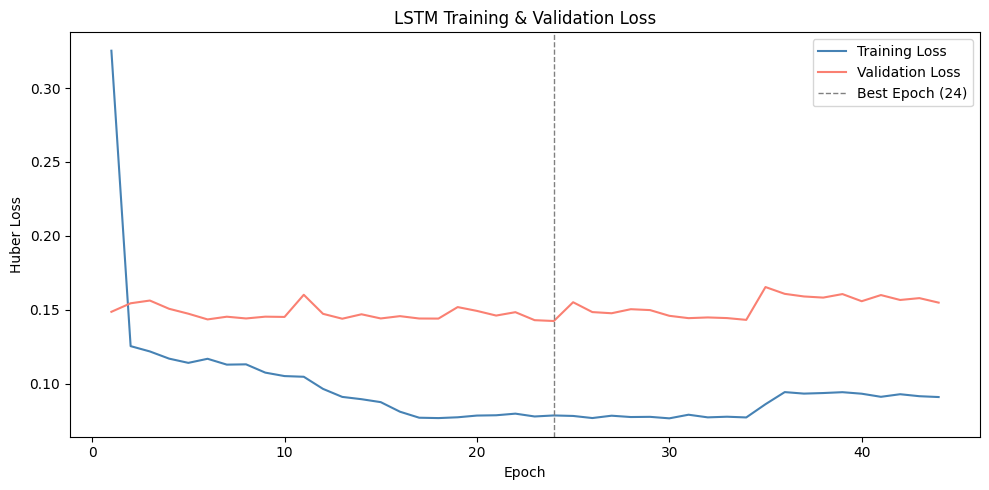

[PASS] Cell 32 | Epochs plotted: 44 | Min train_loss: 0.076426 | Min val_loss: 0.142301


In [33]:
### ============================================================
### CELL 32 — TRAINING DIAGNOSTICS
### ============================================================

import matplotlib.pyplot as plt

required_keys = {'loss', 'val_loss'}
assert required_keys.issubset(set(history.history.keys())), \
    f"history missing required keys: {required_keys - set(history.history.keys())}"

epochs_range = range(1, len(history.history['loss']) + 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(epochs_range, history.history['loss'], label='Training Loss', color='steelblue')
ax.plot(epochs_range, history.history['val_loss'], label='Validation Loss', color='salmon')
ax.axvline(best_epoch, color='gray', linestyle='--', linewidth=1, label=f'Best Epoch ({best_epoch})')
ax.set_xlabel('Epoch')
ax.set_ylabel('Huber Loss')
ax.set_title('LSTM Training & Validation Loss')
ax.legend()
plt.tight_layout()
plt.show()

print(f"[PASS] Cell 32 | Epochs plotted: {len(epochs_range)} | "
      f"Min train_loss: {min(history.history['loss']):.6f} | "
      f"Min val_loss: {min(history.history['val_loss']):.6f}")

In [34]:
### ============================================================
### CELL 33 — TEST PREDICTIONS
### ============================================================

lstm_val_pred  = lstm_model.predict(X_val,  verbose=0).flatten()
lstm_test_pred = lstm_model.predict(X_test, verbose=0).flatten()

assert lstm_val_pred.shape == y_val.shape, "LSTM val prediction shape mismatch"
assert lstm_test_pred.shape == y_test.shape, "LSTM test prediction shape mismatch"
assert not np.isnan(lstm_val_pred).any(), "NaN in LSTM val predictions"
assert not np.isnan(lstm_test_pred).any(), "NaN in LSTM test predictions"
assert np.isfinite(lstm_val_pred).all(), "Non-finite values in LSTM val predictions"
assert np.isfinite(lstm_test_pred).all(), "Non-finite values in LSTM test predictions"

print("=" * 70)
print("LSTM PREDICTION REPORT")
print("=" * 70)
print(f"  Validation preds : n={len(lstm_val_pred):,} | "
      f"min={lstm_val_pred.min():.6f} | max={lstm_val_pred.max():.6f} | mean={lstm_val_pred.mean():.6f}")
print(f"  Test preds       : n={len(lstm_test_pred):,} | "
      f"min={lstm_test_pred.min():.6f} | max={lstm_test_pred.max():.6f} | mean={lstm_test_pred.mean():.6f}")
print("\n✅ Predictions stored in `lstm_val_pred`, `lstm_test_pred`. Shapes, NaNs, finiteness verified.")

LSTM PREDICTION REPORT
  Validation preds : n=31,726 | min=-0.003903 | max=83.422546 | mean=1.098345
  Test preds       : n=31,726 | min=-0.003903 | max=83.456169 | mean=1.709748

✅ Predictions stored in `lstm_val_pred`, `lstm_test_pred`. Shapes, NaNs, finiteness verified.


In [35]:
### ============================================================
### CELL 34 — PREDICTION CALIBRATION
### ============================================================

def calibration_report(y_true, y_pred, label):
    error      = y_pred - y_true
    mean_err   = error.mean()
    median_err = np.median(error)
    std_err    = error.std()
    pred_mean  = y_pred.mean()
    actual_mean = y_true.mean()

    return {
        'split'           : label,
        'Mean_Error'      : mean_err,
        'Median_Error'    : median_err,
        'Error_Std'       : std_err,
        'Pred_Mean'       : pred_mean,
        'Actual_Mean'     : actual_mean,
        'Mean_Bias'       : pred_mean - actual_mean,
    }

calibration_results = [
    calibration_report(y_val,  lstm_val_pred,  'validation'),
    calibration_report(y_test, lstm_test_pred, 'test'),
]
calibration_df = pd.DataFrame(calibration_results)

assert not calibration_df[['Mean_Error', 'Median_Error', 'Error_Std']].isna().any().any(), \
    "NaN detected in calibration diagnostics"

print("=" * 70)
print("PREDICTION CALIBRATION — VALIDATION & TEST")
print("=" * 70)
print(calibration_df.to_string(index=False))
print("\n✅ Calibration diagnostics stored in `calibration_df`. Prediction quality only — no strategy logic.")

PREDICTION CALIBRATION — VALIDATION & TEST
     split  Mean_Error  Median_Error  Error_Std  Pred_Mean  Actual_Mean  Mean_Bias
validation    0.090571     -0.004035   2.649382   1.098345     1.007774   0.090571
      test   -0.091184     -0.004009   4.304885   1.709748     1.800932  -0.091184

✅ Calibration diagnostics stored in `calibration_df`. Prediction quality only — no strategy logic.


In [36]:
### ============================================================
### CELL 35 — DIRECTIONAL ACCURACY
### ============================================================

def directional_report(y_true, y_pred, label):
    actual_dir = np.where(y_true >= 0, 'Up', 'Down')
    pred_dir   = np.where(y_pred >= 0, 'Up', 'Down')

    dir_acc = (actual_dir == pred_dir).mean()

    cm = pd.crosstab(
        pd.Series(actual_dir, name='Actual'),
        pd.Series(pred_dir,   name='Predicted'),
    ).reindex(index=['Up', 'Down'], columns=['Up', 'Down'], fill_value=0)

    return dir_acc, cm

val_dir_acc,  val_confusion  = directional_report(y_val,  lstm_val_pred,  'validation')
test_dir_acc, test_confusion = directional_report(y_test, lstm_test_pred, 'test')

assert 0.0 <= val_dir_acc <= 1.0, "Validation directional accuracy out of bounds"
assert 0.0 <= test_dir_acc <= 1.0, "Test directional accuracy out of bounds"
assert val_confusion.values.sum() == len(y_val), "Validation confusion matrix row count mismatch"
assert test_confusion.values.sum() == len(y_test), "Test confusion matrix row count mismatch"

print("=" * 70)
print("DIRECTIONAL ACCURACY REPORT")
print("=" * 70)
print(f"\nValidation Directional Accuracy : {val_dir_acc:.4f}")
print("Validation Confusion Matrix (Actual rows x Predicted cols):")
print(val_confusion.to_string())

print(f"\nTest Directional Accuracy       : {test_dir_acc:.4f}")
print("Test Confusion Matrix (Actual rows x Predicted cols):")
print(test_confusion.to_string())

print("\n✅ Pure evaluation complete. No threshold optimization applied.")

DIRECTIONAL ACCURACY REPORT

Validation Directional Accuracy : 0.4907
Validation Confusion Matrix (Actual rows x Predicted cols):
Predicted   Up   Down
Actual               
Up         410  16142
Down        15  15159

Test Directional Accuracy       : 0.5073
Test Confusion Matrix (Actual rows x Predicted cols):
Predicted   Up   Down
Actual               
Up         625  15593
Down        38  15470

✅ Pure evaluation complete. No threshold optimization applied.
